In [ ]:
#Import libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    balanced_accuracy_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

import sklearn

print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 2.2.3
scikit-learn: 1.6.1


In [ ]:
#Download the dataset
DATA_URL = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/"
    "Telco-Customer-Churn.csv"
)

df = pd.read_csv(DATA_URL)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
#Validate the raw data
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

print("\nTarget distribution:")
print(df["Churn"].value_counts(dropna=False))

print("\nTarget percentage:")
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))

Shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing values:
customerID 

In [ ]:
#Correct data types and validate labels
df = df.copy()

# Convert whitespace-only TotalCharges values to missing values
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)

# Convert to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Handle new-customer records with no accumulated charges.
# Document this assumption in the final README.
df.loc[
    df["tenure"].eq(0) & df["TotalCharges"].isna(),
    "TotalCharges"
] = 0

# Check whether any other values failed numeric conversion
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

# Validate the target labels
print("Target labels:", df["Churn"].unique())

# Encode the binary target
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

assert df["Churn"].notna().all(), "Unexpected or missing target labels!"
assert df["customerID"].is_unique, "Duplicate customer IDs found!"
assert df["Churn"].isin([0, 1]).all()

print("Cleaned shape:", df.shape)
print("Churn rate:", round(df["Churn"].mean() * 100, 2), "%")
display(df.head())

Missing TotalCharges: 0
Target labels: ['No' 'Yes']
Cleaned shape: (7043, 21)
Churn rate: 26.54 %


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [ ]:
#Summary statistics
display(df.describe(include="all").T)

print("Numeric columns:")
display(df.select_dtypes(include=np.number).head())

print("Unique values per column:")
display(df.nunique().sort_values())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Numeric columns:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
0,0,1,29.85,29.85,0
1,0,34,56.95,1889.50,0
2,0,2,53.85,108.15,1
3,0,45,42.30,1840.75,0
4,0,2,70.70,151.65,1


Unique values per column:


,0
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
PhoneService,2
PaperlessBilling,2
Churn,2
MultipleLines,3
TechSupport,3
StreamingTV,3


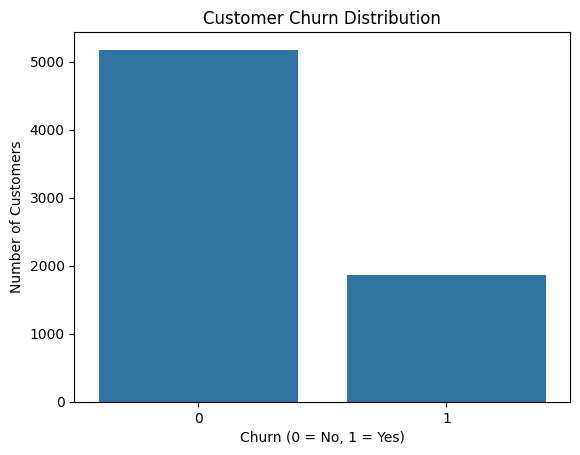

Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [ ]:
#Visualize the target distribution
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

print(df["Churn"].value_counts(normalize=True).mul(100).round(2))

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


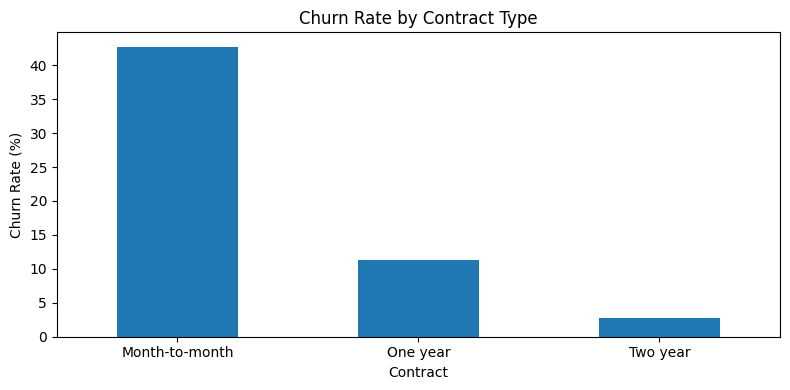

In [ ]:
#Churn by contract type
contract_churn = (
    df.groupby("Contract", observed=True)["Churn"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print(contract_churn.round(2))

contract_churn.plot(kind="bar", figsize=(8, 4))
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

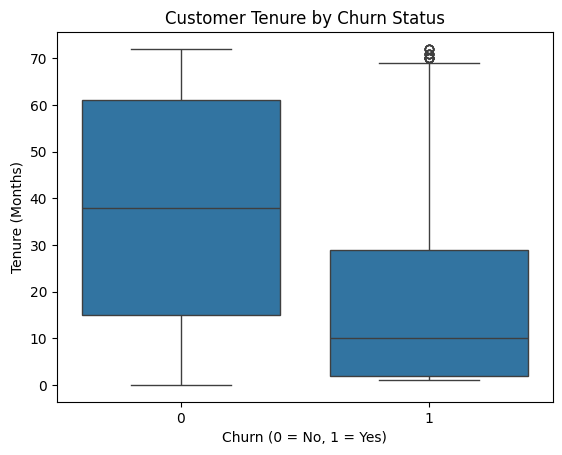

In [ ]:
#Churn versus tenure
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Tenure (Months)")
plt.show()

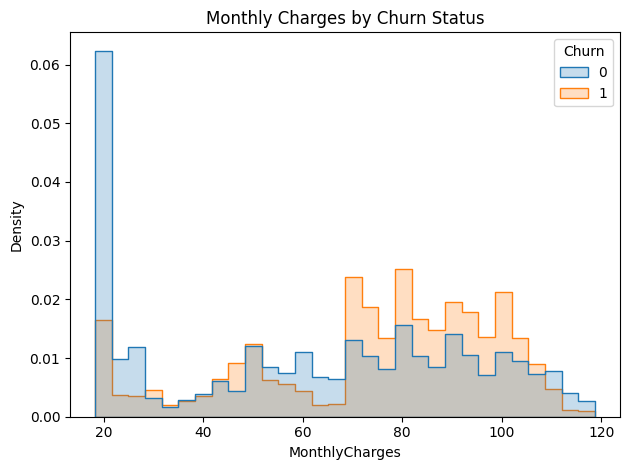

In [ ]:
#Churn by monthly charges
sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Monthly Charges by Churn Status")
plt.tight_layout()
plt.show()


Churn rate by Contract:


,Churn Rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


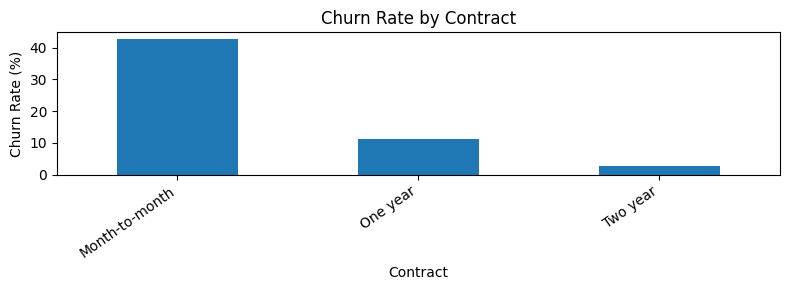


Churn rate by InternetService:


,Churn Rate (%)
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40


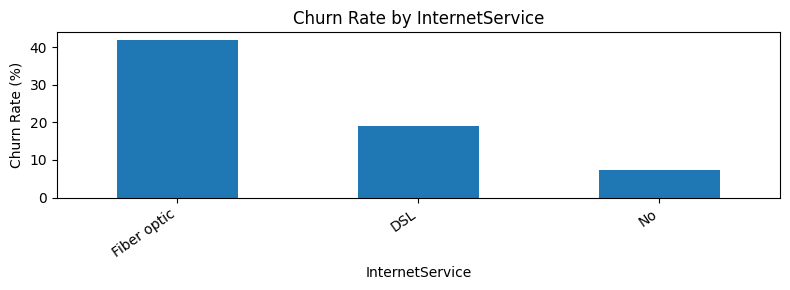


Churn rate by PaymentMethod:


,Churn Rate (%)
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


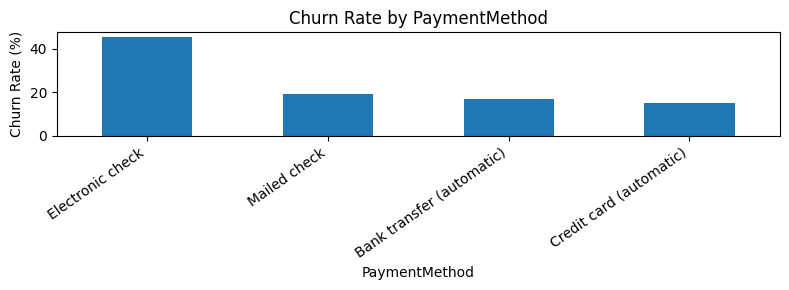


Churn rate by TechSupport:


,Churn Rate (%)
TechSupport,
No,41.64
Yes,15.17
No internet service,7.40


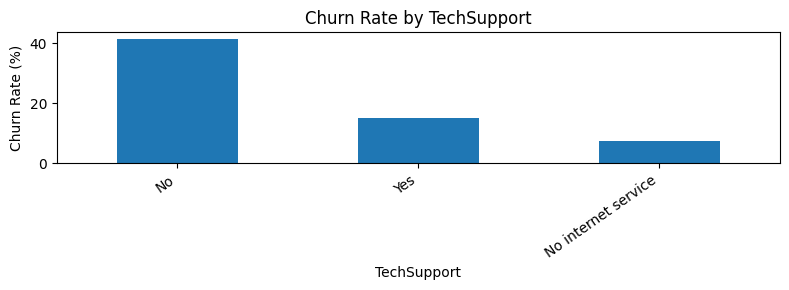


Churn rate by OnlineSecurity:


,Churn Rate (%)
OnlineSecurity,
No,41.77
Yes,14.61
No internet service,7.40


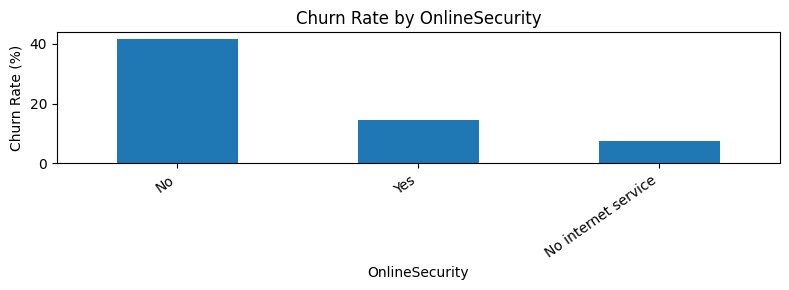


Churn rate by PaperlessBilling:


,Churn Rate (%)
PaperlessBilling,
Yes,33.57
No,16.33


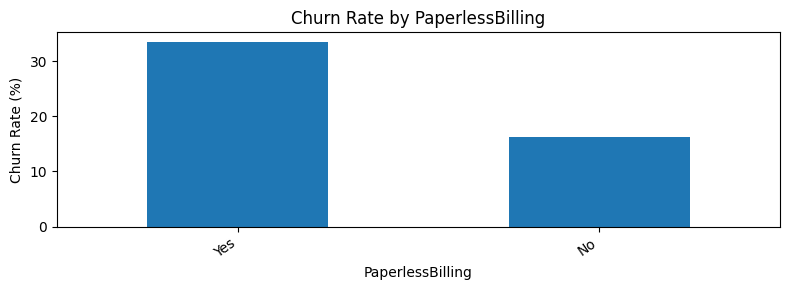

In [ ]:
#Churn across several categorical features
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling"
]

for col in categorical_features:
    rates = (
        df.groupby(col, dropna=False)["Churn"]
          .mean()
          .mul(100)
          .sort_values(ascending=False)
    )

    print(f"\nChurn rate by {col}:")
    display(rates.round(2).to_frame("Churn Rate (%)"))

    rates.plot(kind="bar", figsize=(8, 3))
    plt.title(f"Churn Rate by {col}")
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

In [ ]:
#Create train, validation and test sets
# Customer ID is an identifier, not a predictive feature
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].astype(int)

# First separate the final test set (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Divide the remaining 80% into 60% train and 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

for name, X_part, y_part in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(
        name,
        "| rows:", len(X_part),
        "| churn rate:", round(y_part.mean() * 100, 2), "%"
    )

Train | rows: 4225 | churn rate: 26.53 %
Validation | rows: 1409 | churn rate: 26.54 %
Test | rows: 1409 | churn rate: 26.54 %


In [ ]:
#Build the preprocessing pipeline
#Define the transformations
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features)
    ],
    remainder="drop"
)

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
#Train baseline and candidate models
#Define and fit models
models = {
    "Dummy Baseline": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", DummyClassifier(strategy="prior"))
    ]),

    "Logistic Regression": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Fitted: {name}")

Fitted: Dummy Baseline
Fitted: Logistic Regression
Fitted: Random Forest


In [ ]:
#Compare validation performance
validation_results = []

for name, model in models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    validation_results.append({
        "Model": name,
        "ROC_AUC": roc_auc_score(y_val, probabilities),
        "Average_Precision": average_precision_score(
            y_val, probabilities
        ),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_val, predictions
        )
    })

validation_results = pd.DataFrame(validation_results)

display(
    validation_results.sort_values(
        "Average_Precision", ascending=False
    ).round(4)
)

,Model,ROC_AUC,Average_Precision,Precision,Recall,F1,Balanced_Accuracy
1,Logistic Regression,0.8364,0.6426,0.5157,0.7888,0.6237,0.7606
2,Random Forest,0.8321,0.6251,0.5618,0.6684,0.6105,0.7400
0,Dummy Baseline,0.5000,0.2654,0.0000,0.0000,0.0000,0.5000


In [ ]:
#Select the model and threshold
# Select the best candidate using validation average precision.
# The dummy baseline is excluded from model selection.
candidate_results = (
    validation_results[
        validation_results["Model"] != "Dummy Baseline"
    ]
    .sort_values("Average_Precision", ascending=False)
)

best_model_name = candidate_results.iloc[0]["Model"]
best_model = models[best_model_name]

print("Selected model:", best_model_name)

from sklearn.metrics import precision_recall_curve

val_probabilities = best_model.predict_proba(X_val)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(
    y_val, val_probabilities
)

# F2 is calculated for thresholds; the last precision/recall point
# has no corresponding threshold.
f2_scores = (
    5 * precisions[:-1] * recalls[:-1]
    / (4 * precisions[:-1] + recalls[:-1] + 1e-12)
)

best_idx = np.argmax(f2_scores)
selected_threshold = thresholds[best_idx]

print("Selected threshold:", round(selected_threshold, 4))
print("Validation F2:", round(f2_scores[best_idx], 4))
print("Validation precision:", round(precisions[best_idx], 4))
print("Validation recall:", round(recalls[best_idx], 4))

Selected model: Logistic Regression
Selected threshold: 0.3052
Validation F2: 0.7407
Validation precision: 0.4231
Validation recall: 0.9118


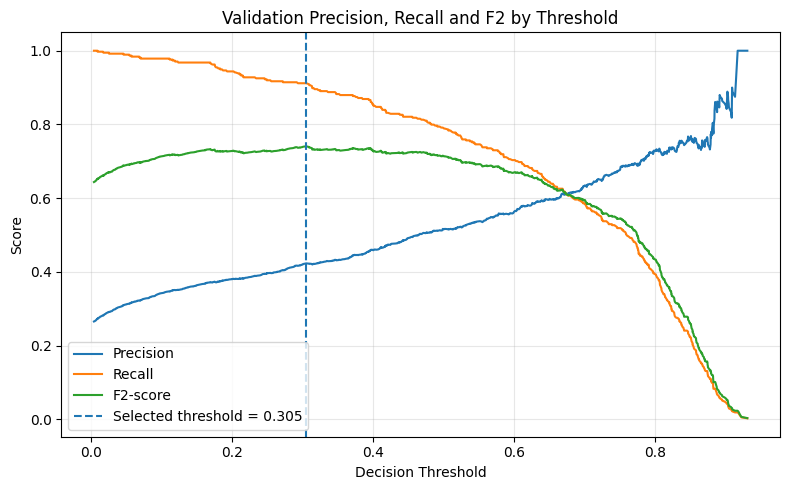

In [ ]:
#Visualize the trade-off
plt.figure(figsize=(8, 5))

plt.plot(
    thresholds,
    precisions[:-1],
    label="Precision"
)
plt.plot(
    thresholds,
    recalls[:-1],
    label="Recall"
)
plt.plot(
    thresholds,
    f2_scores,
    label="F2-score"
)

plt.axvline(
    selected_threshold,
    linestyle="--",
    label=f"Selected threshold = {selected_threshold:.3f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Validation Precision, Recall and F2 by Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Final model: Logistic Regression
Decision threshold: 0.3052

Classification report:
              precision    recall  f1-score   support

    No Churn       0.96      0.57      0.71      1035
       Churn       0.44      0.93      0.59       374

    accuracy                           0.66      1409
   macro avg       0.70      0.75      0.65      1409
weighted avg       0.82      0.66      0.68      1409

ROC-AUC: 0.8428
Average Precision: 0.6331
Balanced Accuracy: 0.7475


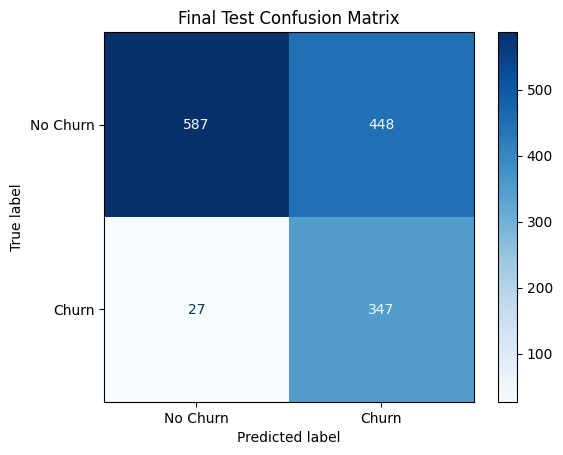

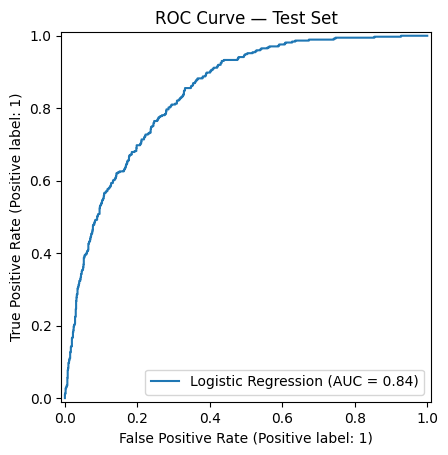

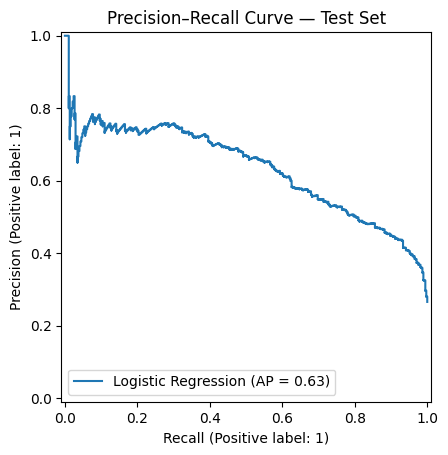

In [ ]:
#Evaluate the final model
from sklearn.metrics import ConfusionMatrixDisplay

test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

print("Final model:", best_model_name)
print("Decision threshold:", round(selected_threshold, 4))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

print("ROC-AUC:",
      round(roc_auc_score(y_test, test_probabilities), 4))

print("Average Precision:",
      round(average_precision_score(y_test, test_probabilities), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, test_predictions), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Final Test Confusion Matrix")
plt.show()

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities,
    name=best_model_name
)
plt.title("ROC Curve — Test Set")
plt.show()

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    name=best_model_name
)
plt.title("Precision–Recall Curve — Test Set")
plt.show()

In [ ]:
#Extract Logistic Regression coefficients
logistic_model = models["Logistic Regression"]

feature_names = (
    logistic_model.named_steps["preprocess"]
    .get_feature_names_out()
)

coefficients = (
    logistic_model.named_steps["model"]
    .coef_[0]
)

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

display(
    coefficient_df.sort_values(
        "Absolute_Coefficient", ascending=False
    ).head(15)
)


,Feature,Coefficient,Absolute_Coefficient
1,numeric__tenure,-1.231458,1.231458
38,categorical__Contract_Two year,-0.859525,0.859525
36,categorical__Contract_Month-to-month,0.736618,0.736618
16,categorical__InternetService_Fiber optic,0.590012,0.590012
3,numeric__TotalCharges,0.568531,0.568531
15,categorical__InternetService_DSL,-0.540252,0.540252
2,numeric__MonthlyCharges,-0.404534,0.404534
12,categorical__MultipleLines_No,-0.248724,0.248724
39,categorical__PaperlessBilling_No,-0.227014,0.227014
17,categorical__InternetService_No,-0.222597,0.222597


,Feature,Importance
1,numeric__tenure,0.126812
36,categorical__Contract_Month-to-month,0.117639
3,numeric__TotalCharges,0.109270
2,numeric__MonthlyCharges,0.086927
38,categorical__Contract_Two year,0.056829
18,categorical__OnlineSecurity_No,0.053322
27,categorical__TechSupport_No,0.041161
16,categorical__InternetService_Fiber optic,0.040481
43,categorical__PaymentMethod_Electronic check,0.032064
21,categorical__OnlineBackup_No,0.017957


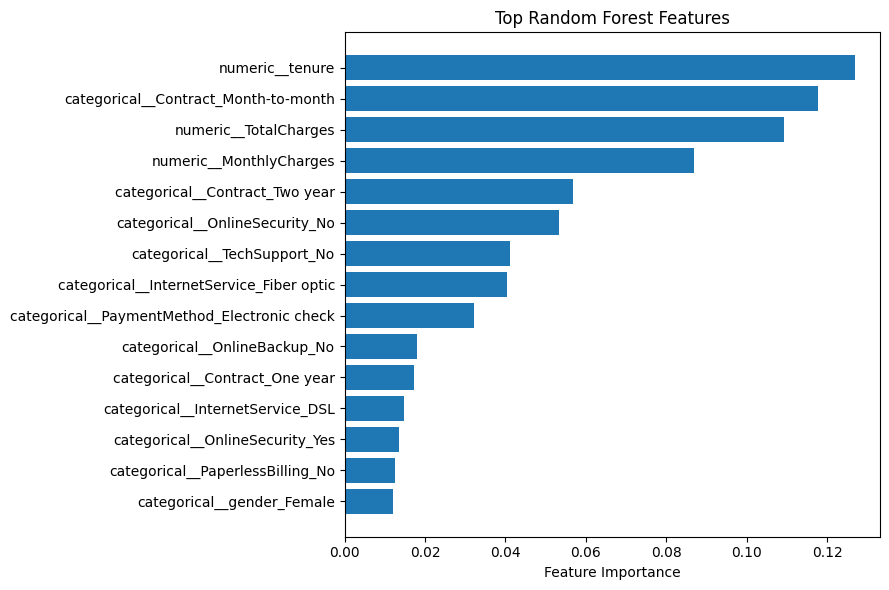

In [ ]:
#Extract Random Forest feature importance
rf_model = models["Random Forest"]

rf_feature_names = (
    rf_model.named_steps["preprocess"]
    .get_feature_names_out()
)

rf_importances = (
    rf_model.named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top Random Forest Features")
plt.tight_layout()
plt.show()

In [ ]:
#Turn predictions into a business analysis
test_results = X_test.copy()

test_results["Actual_Churn"] = y_test
test_results["Churn_Probability"] = test_probabilities
test_results["Predicted_Churn"] = test_predictions

test_results["Prediction_Result"] = np.select(
    [
        (test_results["Actual_Churn"] == 1) &
        (test_results["Predicted_Churn"] == 1),

        (test_results["Actual_Churn"] == 0) &
        (test_results["Predicted_Churn"] == 1),

        (test_results["Actual_Churn"] == 1) &
        (test_results["Predicted_Churn"] == 0)
    ],
    [
        "Correctly flagged churner",
        "False alarm",
        "Missed churner"
    ],
    default="Correctly identified non-churner"
)

display(
    test_results.sort_values(
        "Churn_Probability", ascending=False
    ).head(20)
)

print(
    "Flagged customers:",
    int(test_results["Predicted_Churn"].sum())
)

print(
    "Actual churners in test set:",
    int(test_results["Actual_Churn"].sum())
)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Churn_Probability,Predicted_Churn,Prediction_Result
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,0.933528,1,Correctly flagged churner
6866,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,1,0.923916,1,Correctly flagged churner
3727,Female,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,96.60,291.90,1,0.922731,1,Correctly flagged churner
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,0.921219,1,Correctly flagged churner
3346,Female,1,No,No,2,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,84.05,186.05,0,0.920398,1,False alarm
2631,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,0.920074,1,Correctly flagged churner
935,Female,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,83.25,308.05,0,0.918145,1,False alarm
6365,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,101.95,700.85,1,0.918021,1,Correctly flagged churner
2797,Male,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,100.95,329.95,1,0.916499,1,Correctly flagged churner
582,Female,1,No,No,4,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,89.20,346.20,1,0.916009,1,Correctly flagged churner


Flagged customers: 795
Actual churners in test set: 374


In [ ]:
#Save the model and results
import joblib
import json
from pathlib import Path

Path("artifacts").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

joblib.dump(best_model, "artifacts/churn_model.joblib")

metadata = {
    "model_name": best_model_name,
    "decision_threshold": float(selected_threshold),
    "target": "Churn",
    "random_state": 42,
    "test_roc_auc": float(
        roc_auc_score(y_test, test_probabilities)
    ),
    "test_average_precision": float(
        average_precision_score(y_test, test_probabilities)
    ),
    "test_f1": float(
        f1_score(y_test, test_predictions, zero_division=0)
    ),
    "test_recall": float(
        recall_score(y_test, test_predictions, zero_division=0)
    )
}

with open("artifacts/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

test_results.to_csv("results/test_predictions.csv", index=False)

print("Saved model, metadata and test predictions.")

Saved model, metadata and test predictions.
